# KI-Labor – Assignment 7: RNN vs. DistilBERT (TweetEval Emotion)

**Ziel:** Dieselbe Emotionsklassifikation wie in Assignment 6 (4 Klassen: anger, joy, optimism, sadness), diesmal mit einem **vortrainierten Transformer (DistilBERT)**, der auf unseren Daten fine-getunt wird. Danach Vergleich mit LSTM/GRU aus Assignment 6 (Ergebnisse übernommen, nicht neu trainiert).

**Ablauf (wie im Hugging-Face-Tutorial „Text classification“):**
1. Daten laden → 2. Tokenisieren (spaCy + DistilBERT-Tokenizer) → 3. Modell laden → 4. Fine-Tuning mit `Trainer` → 5. Lernkurven → 6. Testset einmal auswerten → 7. Vergleich mit Assignment 6

**Faire Auswahl:** Lernrate und Epoche werden nur über das **Validierungsset** gewählt; das Testset wird erst ganz am Ende **einmal** benutzt.

In [1]:
# --- Standardbibliothek ---
import os        # Pfade zusammenbauen
import shutil    # Ordner löschen (Checkpoints)
import time      # Zeitmessung für Training/Inferenz

# --- Externe Bibliotheken ---
import matplotlib.pyplot as plt  # Plots
import numpy as np               # Arrays, argmax, bincount
import torch                     # PyTorch: Tensoren, GPU
from datasets import Dataset, DatasetDict           # Hugging-Face-Datensätze (train/val/test)
from sklearn.metrics import accuracy_score, f1_score  # Metriken wie in Assignment 6
from transformers import (AutoModelForSequenceClassification,  # vortrainiertes Modell + Klassifikationskopf
                          AutoTokenizer,                       # passender Tokenizer zum Modell
                          DataCollatorWithPadding,             # füllt jeden Batch auf gleiche Länge auf
                          PrinterCallback, Trainer, TrainerCallback, TrainingArguments,  # Trainingsschleife
                          set_seed)                            # Zufall reproduzierbar machen
import transformers

import datasets

# Nur Ausgaben-Kosmetik: Warnungen und Fortschrittsbalken ausblenden
transformers.logging.set_verbosity_error()  # Lade-Report/Warnungen ausblenden
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()

# Fester Seed → gleiche Gewichtsinitialisierung des Kopfes, gleiche Batch-Reihenfolge
SEED = 42
set_seed(SEED)

# Auf der GPU rechnen, falls vorhanden (DistilBERT ist ~100x größer als das RNN)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print(f"PyTorch {torch.__version__} | transformers {transformers.__version__} | Gerät: {DEVICE} ({GPU_NAME})")

/home/debian/jupyter-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1+cu130 | transformers 5.22.2 | Gerät: cuda (NVIDIA GeForce RTX 5060 Ti)


## 1. Daten laden (identischer Split wie in Assignment 6)

Wir lesen exakt dieselben Dateien wie in Assignment 6 (gleicher Train/Val/Test-Split, gleiche Vorverarbeitung). Nur so sind die Ergebnisse direkt vergleichbar.

In [2]:
# Gleicher Ordner wie in Assignment 6 → identischer Datensplit
DATA_DIR = "../assignment6/tweeteval/datasets/emotion"


def read_lines(name):
    # liest eine Textdatei zeilenweise (eine Zeile = ein Tweet bzw. ein Label)
    with open(os.path.join(DATA_DIR, name), encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]


# mapping.txt enthält "0\tanger", "1\tjoy", ... → Liste der Klassennamen
with open(os.path.join(DATA_DIR, "mapping.txt")) as f:
    CLASSES = [line.split("\t")[1].strip() for line in f if line.strip()]
NUM_CLASSES = len(CLASSES)                         # 4 Klassen
id2label = dict(enumerate(CLASSES))                # 0 → "anger", ... (wird im Modell gespeichert)
label2id = {c: i for i, c in id2label.items()}     # "anger" → 0, ...


def preprocess(text):
    # gleiche Normalisierung wie in Assignment 6 / TweetEval-Tutorial
    # @Nutzername → "@user", Links → "http" (Namen/URLs tragen keine Emotion)
    new_text = []
    for t in text.split(" "):
        t = "@user" if t.startswith("@") and len(t) > 1 else t
        t = "http" if t.startswith("http") else t
        new_text.append(t)
    return " ".join(new_text)


# Texte und Labels der drei Splits einlesen
splits = {}
for split in ["train", "val", "test"]:
    texts = read_lines(f"{split}_text.txt")
    labels = [int(x) for x in read_lines(f"{split}_labels.txt")]
    assert len(texts) == len(labels)  # Sicherheitscheck: jede Zeile hat ein Label
    splits[split] = (texts, labels)

# In ein Hugging-Face-DatasetDict umwandeln (Spalten "text" und "label"), damit der Trainer damit arbeiten kann
raw = DatasetDict({s: Dataset.from_dict({"text": [preprocess(t) for t in tx], "label": lb})
                   for s, (tx, lb) in splits.items()})
print("Klassen:", CLASSES)
print(raw)

# Klassenverteilung → Daten sind unausgeglichen (anger ~40 %, optimism ~9 %) → deshalb zusätzlich Macro-F1
for split, (texts, labels) in splits.items():
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    print(f"{split:5s}: " + ", ".join(f"{c}={n} ({n / len(labels):.0%})" for c, n in zip(CLASSES, counts)))

Klassen: ['anger', 'joy', 'optimism', 'sadness']
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 3257
    })
    val: Dataset({
        features: ['text', 'label'],
        num_rows: 374
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1421
    })
})
train: anger=1400 (43%), joy=708 (22%), optimism=294 (9%), sadness=855 (26%)
val  : anger=160 (43%), joy=97 (26%), optimism=28 (7%), sadness=89 (24%)
test : anger=558 (39%), joy=358 (25%), optimism=123 (9%), sadness=382 (27%)


## 2. Tokenisierung: spaCy + DistilBERT-Tokenizer

1. **spaCy** (`spacy.blank("en")`, nur der regelbasierte Tokenizer) zerlegt jeden Tweet in Wörter und Satzzeichen (z. B. `can't` → `ca` + `n't`, `#furious` → `#` + `furious`).
2. Der **DistilBERT-Tokenizer** bekommt diese Wörter (`is_split_into_words=True`), zerlegt sie in WordPiece-Subwörter, bildet sie auf IDs ab und fügt `[CLS]`/`[SEP]` sowie die Attention-Mask hinzu.

Schritt 2 lässt sich nicht durch spaCy ersetzen: Die IDs müssen zum Vokabular und zur Embedding-Tabelle des vortrainierten Modells passen.

**Unterschied zu Assignment 6:** Dort gab es ein eigenes Wortvokabular (3 000 Wörter), unbekannte Wörter wurden zu `<unk>`. WordPiece zerlegt unbekannte Wörter stattdessen in bekannte Teilstücke (`autocorrect` → `auto ##cor ##re ##ct`), dadurch geht kaum Information verloren.

In [3]:
import spacy

# Leere englische spaCy-Pipeline: enthält nur den regelbasierten Tokenizer (kein Download eines Modells nötig)
nlp = spacy.blank("en")

# Name des vortrainierten Modells auf dem Hugging-Face-Hub (wie im Tutorial)
MODEL_NAME = "distilbert/distilbert-base-uncased"
# Tokenizer MUSS zum Modell passen: gleiches Vokabular (30 522 WordPiece-Einträge), gleiche Kleinschreibung
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def spacy_words(text):
    # Schritt 1: spaCy zerlegt den Tweet in Wörter/Satzzeichen (Leerzeichen-Tokens werden verworfen)
    return [t.text for t in nlp(text) if not t.is_space]


# Beispiel: was passiert mit einem Tweet in jedem Schritt?
example = raw["train"][1]["text"]
# Schritt 2: DistilBERT-Tokenizer bekommt die spaCy-Wörter und macht daraus Subwörter + IDs
enc = tokenizer(spacy_words(example), is_split_into_words=True)
print("Text:          ", example)
print("spaCy-Tokens:  ", spacy_words(example))
print("WordPiece:     ", tokenizer.convert_ids_to_tokens(enc["input_ids"]))  # "##" = Fortsetzung eines Wortes
print("input_ids:     ", enc["input_ids"])        # Zeilennummern in der Embedding-Tabelle des Modells
print("attention_mask:", enc["attention_mask"])   # 1 = echtes Token, 0 = Padding (hier noch kein Padding)


def tokenize_fn(batch):
    # wird von .map() auf jeweils viele Tweets gleichzeitig angewendet
    words = [spacy_words(t) for t in batch["text"]]
    # truncation=True: zu lange Texte auf max. 512 Tokens kürzen (Tweets sind viel kürzer, greift praktisch nie)
    return tokenizer(words, is_split_into_words=True, truncation=True)


# Alle drei Splits tokenisieren; die Textspalte wird danach nicht mehr gebraucht
# → übrig bleiben "label", "input_ids", "attention_mask"
tokenized = raw.map(tokenize_fn, batched=True, remove_columns=["text"])

# Padding erst beim Batch-Bau: jeder Batch wird nur auf die Länge seines längsten Tweets aufgefüllt
# (spart Rechenzeit gegenüber festem Padding auf 512); die attention_mask markiert die Füll-Tokens mit 0
collator = DataCollatorWithPadding(tokenizer=tokenizer)  # dynamisches Padding pro Batch

Text:           My roommate: it's okay that we can't spell because we have autocorrect. #terrible #firstworldprobs 
spaCy-Tokens:   ['My', 'roommate', ':', 'it', "'s", 'okay', 'that', 'we', 'ca', "n't", 'spell', 'because', 'we', 'have', 'autocorrect', '.', '#', 'terrible', '#', 'firstworldprobs']
WordPiece:      ['[CLS]', 'my', 'roommate', ':', 'it', "'", 's', 'okay', 'that', 'we', 'ca', 'n', "'", 't', 'spell', 'because', 'we', 'have', 'auto', '##cor', '##re', '##ct', '.', '#', 'terrible', '#', 'first', '##world', '##pro', '##bs', '[SEP]']
input_ids:      [101, 2026, 18328, 1024, 2009, 1005, 1055, 3100, 2008, 2057, 6187, 1050, 1005, 1056, 6297, 2138, 2057, 2031, 8285, 27108, 2890, 6593, 1012, 1001, 6659, 1001, 2034, 11108, 21572, 5910, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 3. Modell: vortrainierter DistilBERT-Encoder + Klassifikationskopf

`AutoModelForSequenceClassification` lädt den vortrainierten DistilBERT-Encoder (6 Transformer-Schichten, 768-dim., 12 Attention-Heads) und setzt einen **neuen, zufällig initialisierten Klassifikationskopf** (4 Ausgänge) obendrauf. Klassifiziert wird über den Vektor des `[CLS]`-Tokens.

**Vollständiges Fine-Tuning:** Alle Gewichte (Encoder + Kopf) werden trainiert, nichts ist eingefroren.

In [4]:
def build_model():
    # lädt die vortrainierten Gewichte und hängt einen neuen Kopf mit NUM_CLASSES Ausgängen an
    # (als Funktion, weil wir für jede Lernrate ein frisches Modell brauchen)
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id)


# Nur zum Zählen der Parameter einmal laden
model = build_model()
n_total = sum(p.numel() for p in model.parameters())                       # alle Gewichte
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)    # davon trainierbar
print(f"Parameter gesamt:  {n_total:,}")
print(f"davon trainierbar: {n_train:,} (vollständiges Fine-Tuning, nichts eingefroren)")
del model  # Speicher freigeben, das eigentliche Training baut ein neues Modell

Parameter gesamt:  66,956,548
davon trainierbar: 66,956,548 (vollständiges Fine-Tuning, nichts eingefroren)


## 4. Fine-Tuning mit `Trainer`

Wie im Tutorial übernimmt der `Trainer` die Trainingsschleife (Forward, Loss, Backward, AdamW-Schritt, lineare LR-Absenkung). Nach jeder Epoche wird auf dem Validierungsset ausgewertet; am Ende wird automatisch der Checkpoint mit dem **besten Val-Macro-F1** geladen (`load_best_model_at_end`).

**Hyperparameter-Wahl nur auf Validierung:** zwei Lernraten (2e-5 aus dem Tutorial, 5e-5), je 5 Epochen. Batchgröße 16 und `weight_decay=0.01` stammen aus dem Tutorial.

In [5]:
BATCH_SIZE = 16                 # wie im Tutorial
EPOCHS = 5                      # vortrainierte Modelle brauchen nur wenige Epochen
LEARNING_RATES = [2e-5, 5e-5]   # kleine LR, damit das Vorwissen nicht "zerstört" wird
RUN_DIR = "./runs"              # temporärer Ordner für Checkpoints


def compute_metrics(eval_pred):
    # wird vom Trainer bei jeder Auswertung aufgerufen
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)  # Klasse mit dem größten Logit = Vorhersage
    # gleiche Metriken wie in Assignment 6: Accuracy und Macro-F1 (Mittel der F1-Werte aller Klassen)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds, average="macro")}


class TrainEvalCallback(TrainerCallback):
    # wertet am Epochenende zusätzlich das Trainingsset aus (Loss/Accuracy für die Lernkurven)
    # Grund: Der Trainer loggt nur den Train-Loss, aber keine Train-Accuracy.
    def __init__(self, trainer):
        self.trainer = trainer

    def on_epoch_end(self, args, state, control, **kwargs):
        # evaluate() setzt die Flags des Trainers zurück → sichern und wiederherstellen
        flags = (control.should_evaluate, control.should_log, control.should_save)
        self.trainer.evaluate(self.trainer.train_dataset, metric_key_prefix="train_eval")
        control.should_evaluate, control.should_log, control.should_save = flags
        return control


def finetune(lr, seed=SEED, epochs=EPOCHS, track_train=True):
    # trainiert ein frisches DistilBERT mit Lernrate lr und gibt Trainer, Verlauf, beste Epoche und Zeit zurück
    set_seed(seed)
    out = os.path.join(RUN_DIR, f"lr{lr:g}_seed{seed}")
    args = TrainingArguments(
        output_dir=out,
        learning_rate=lr,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=128,     # Auswertung braucht keine Gradienten → größere Batches möglich
        num_train_epochs=epochs,
        weight_decay=0.01,                  # leichte L2-Regularisierung (AdamW), wie im Tutorial
        eval_strategy="epoch",              # nach jeder Epoche auf Val auswerten
        save_strategy="epoch",              # nach jeder Epoche Checkpoint speichern
        logging_strategy="epoch",           # Train-Loss pro Epoche loggen
        load_best_model_at_end=True,        # am Ende besten Checkpoint laden (= Early-Stopping-Auswahl)
        metric_for_best_model="f1",         # "bester" = höchster Val-Macro-F1
        save_total_limit=1,                 # nur den besten Checkpoint auf der Platte behalten
        save_only_model=True,               # Optimizer-Zustand nicht speichern (spart Platz)
        seed=seed,
        report_to="none",                   # kein wandb/tensorboard
        disable_tqdm=True,
    )
    trainer = Trainer(model=build_model(), args=args, train_dataset=tokenized["train"],
                      eval_dataset=tokenized["val"],        # Val (nicht Test!) für die Auswahl
                      processing_class=tokenizer,
                      data_collator=collator, compute_metrics=compute_metrics)
    trainer.remove_callback(PrinterCallback)  # keine rohen Log-Dicts ausgeben
    if track_train:
        trainer.add_callback(TrainEvalCallback(trainer))

    # Trainingszeit messen (synchronize: wartet, bis die GPU wirklich fertig ist)
    start = time.perf_counter()
    trainer.train()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    duration = time.perf_counter() - start
    shutil.rmtree(out, ignore_errors=True)  # Checkpoints (je ~270 MB) nicht aufbewahren

    # Verlauf pro Epoche aus dem Log des Trainers herausziehen
    logs = trainer.state.log_history
    hist = {
        "train_loss": [l["loss"] for l in logs if "loss" in l and "epoch" in l and "eval_loss" not in l],  # mittlerer Loss während des Trainings
        "train_eval_loss": [l["train_eval_loss"] for l in logs if "train_eval_loss" in l],  # Loss auf Train nach der Epoche
        "train_acc": [l["train_eval_accuracy"] for l in logs if "train_eval_accuracy" in l],
        "val_loss": [l["eval_loss"] for l in logs if "eval_loss" in l],
        "val_acc": [l["eval_accuracy"] for l in logs if "eval_accuracy" in l],
        "val_f1": [l["eval_f1"] for l in logs if "eval_f1" in l],
    }
    best_epoch = int(np.argmax(hist["val_f1"])) + 1  # Epoche mit dem besten Val-F1 (1-basiert)
    return trainer, hist, best_epoch, duration


# Für jede Lernrate ein eigenes Modell trainieren und Ergebnisse sammeln
sweep = {}
for lr in LEARNING_RATES:
    trainer, hist, best_epoch, duration = finetune(lr)
    sweep[lr] = dict(trainer=trainer, history=hist, best_epoch=best_epoch, time=duration)
    for e in range(EPOCHS):
        print(f"[lr={lr:g}] Epoche {e + 1} | Train-Loss {hist['train_loss'][e]:.3f}, Acc {hist['train_acc'][e]:.3f} | "
              f"Val-Loss {hist['val_loss'][e]:.3f}, Acc {hist['val_acc'][e]:.3f}, F1 {hist['val_f1'][e]:.3f}")
    print(f"[lr={lr:g}] Trainingszeit {duration:.1f} s (inkl. Train-Auswertung) | "
          f"bester Val-F1 {max(hist['val_f1']):.3f} in Epoche {best_epoch}\n")

[lr=2e-05] Epoche 1 | Train-Loss 0.905, Acc 0.832 | Val-Loss 0.654, Acc 0.770, F1 0.687
[lr=2e-05] Epoche 2 | Train-Loss 0.504, Acc 0.901 | Val-Loss 0.633, Acc 0.791, F1 0.727
[lr=2e-05] Epoche 3 | Train-Loss 0.338, Acc 0.941 | Val-Loss 0.685, Acc 0.767, F1 0.703
[lr=2e-05] Epoche 4 | Train-Loss 0.220, Acc 0.965 | Val-Loss 0.719, Acc 0.781, F1 0.721
[lr=2e-05] Epoche 5 | Train-Loss 0.158, Acc 0.970 | Val-Loss 0.730, Acc 0.794, F1 0.740
[lr=2e-05] Trainingszeit 42.6 s (inkl. Train-Auswertung) | bester Val-F1 0.740 in Epoche 5



[lr=5e-05] Epoche 1 | Train-Loss 0.801, Acc 0.869 | Val-Loss 0.672, Acc 0.773, F1 0.710
[lr=5e-05] Epoche 2 | Train-Loss 0.408, Acc 0.951 | Val-Loss 0.628, Acc 0.794, F1 0.722
[lr=5e-05] Epoche 3 | Train-Loss 0.209, Acc 0.979 | Val-Loss 0.819, Acc 0.778, F1 0.717
[lr=5e-05] Epoche 4 | Train-Loss 0.098, Acc 0.988 | Val-Loss 0.957, Acc 0.781, F1 0.728
[lr=5e-05] Epoche 5 | Train-Loss 0.052, Acc 0.992 | Val-Loss 1.018, Acc 0.781, F1 0.725
[lr=5e-05] Trainingszeit 41.4 s (inkl. Train-Auswertung) | bester Val-F1 0.728 in Epoche 4



In [6]:
# Beste Lernrate = die mit dem höchsten Val-Macro-F1 (Testset wird hier NICHT angeschaut)
best_lr = max(sweep, key=lambda lr: max(sweep[lr]["history"]["val_f1"]))
best = sweep[best_lr]
# das andere Modell von der GPU nehmen, um GPU-Speicher freizugeben
for lr in sweep:
    if lr != best_lr:
        sweep[lr]["trainer"].model.cpu()
torch.cuda.empty_cache()
print(f"Gewählt (nur nach Validierung): lr={best_lr:g}, Epoche {best['best_epoch']} "
      f"(Val-F1 {max(best['history']['val_f1']):.3f})")

Gewählt (nur nach Validierung): lr=2e-05, Epoche 5 (Val-F1 0.740)


## 5. Lernkurven

Gestrichelt = Training, durchgezogen = Validierung. Steigt der Val-Loss, während der Train-Loss weiter fällt, beginnt Overfitting. Deshalb wird der Checkpoint nach Val-F1 ausgewählt und nicht einfach die letzte Epoche genommen.

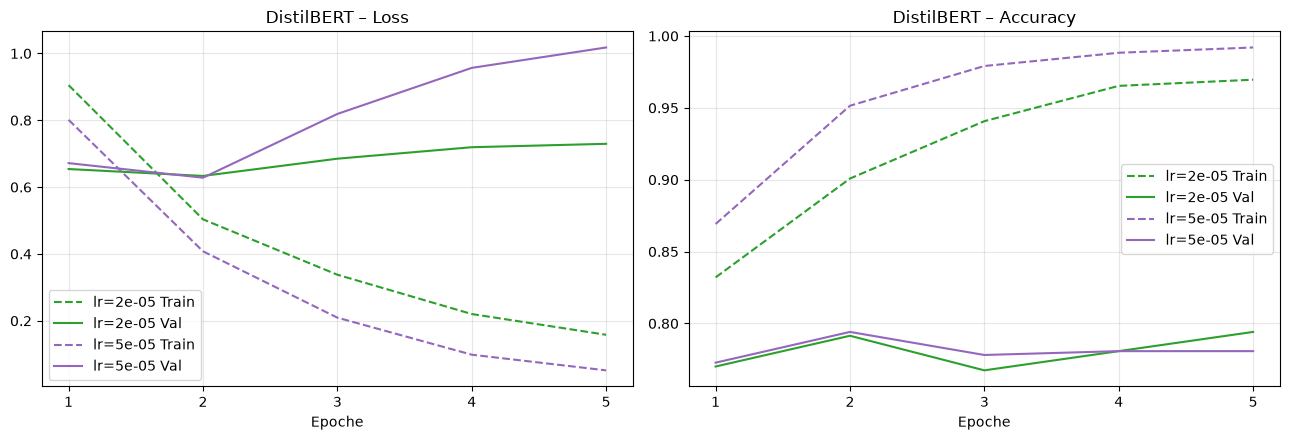

In [7]:
# Links Loss, rechts Accuracy – je Lernrate eine Farbe
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs = range(1, EPOCHS + 1)
colors = dict(zip(LEARNING_RATES, ["tab:green", "tab:purple"]))
for lr, res in sweep.items():
    h, c = res["history"], colors[lr]
    axes[0].plot(epochs, h["train_loss"], c=c, ls="--", label=f"lr={lr:g} Train")  # gestrichelt = Train
    axes[0].plot(epochs, h["val_loss"], c=c, label=f"lr={lr:g} Val")              # durchgezogen = Val
    axes[1].plot(epochs, h["train_acc"], c=c, ls="--", label=f"lr={lr:g} Train")
    axes[1].plot(epochs, h["val_acc"], c=c, label=f"lr={lr:g} Val")
for ax, title in zip(axes, ["Loss", "Accuracy"]):
    ax.set_title(f"DistilBERT – {title}")
    ax.set_xlabel("Epoche")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Einmalige Auswertung auf dem Testset

Erst jetzt, nachdem Lernrate und Epoche feststehen, wird das Testset **genau einmal** ausgewertet. Als Untergrenze dient eine Baseline, die immer die häufigste Klasse vorhersagt.

In [8]:
@torch.no_grad()  # keine Gradienten nötig → schneller, weniger Speicher
def predict(model, dataset, batch_size=128, device=DEVICE):
    # gibt die Logits (Rohwerte vor Softmax) für alle Beispiele des Datensatzes zurück
    model.eval().to(device)  # eval(): Dropout aus
    loader = torch.utils.data.DataLoader(dataset.remove_columns(["label"]), batch_size=batch_size,
                                         collate_fn=collator)  # Labels braucht das Modell hier nicht
    logits = []
    for b in loader:
        # b enthält input_ids und attention_mask → auf das Gerät schieben und durchs Modell
        logits.append(model(**{k: v.to(device) for k, v in b.items()}).logits.float().cpu())
    return torch.cat(logits)


def timed_predict(model, dataset, device, repeats=3, **kw):
    # wie predict(), misst aber zusätzlich die Zeit (bester von mehreren Durchläufen)
    predict(model, dataset.select(range(64)), device=device, **kw)  # Warm-up (erster Aufruf ist langsamer)
    times = []
    for _ in range(repeats):
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        logits = predict(model, dataset, device=device, **kw)
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return logits, min(times)


# Das beste Modell (beste Lernrate, bester Checkpoint) auf dem Testset auswerten
bert_model = best["trainer"].model
test_logits, t_gpu = timed_predict(bert_model, tokenized["test"], DEVICE)
test_preds = test_logits.argmax(1).numpy()     # Vorhersage = Klasse mit größtem Logit
test_targets = np.array(splits["test"][1])     # wahre Labels

bert_test = {
    "acc": accuracy_score(test_targets, test_preds),
    "f1": f1_score(test_targets, test_preds, average="macro"),       # alle Klassen gleich gewichtet
    "per_class": f1_score(test_targets, test_preds, average=None),   # F1 je Klasse
    "preds": test_preds,
}
# Baseline: immer die häufigste Trainingsklasse (anger) vorhersagen
majority = np.bincount(splits["train"][1]).argmax()
print(f"Baseline (immer '{CLASSES[majority]}'): Accuracy {np.mean(test_targets == majority):.3f}")
print(f"DistilBERT Test-Acc {bert_test['acc']:.3f} | Macro-F1 {bert_test['f1']:.3f} | "
      + ", ".join(f"F1 {c} {f:.3f}" for c, f in zip(CLASSES, bert_test["per_class"])))

Baseline (immer 'anger'): Accuracy 0.393
DistilBERT Test-Acc 0.801 | Macro-F1 0.760 | F1 anger 0.844, F1 joy 0.816, F1 optimism 0.591, F1 sadness 0.787


### Inferenzzeit

Gesamtes Testset (1 421 Tweets) auf GPU und CPU. Assignment 6 lief auf der CPU, deshalb ist die CPU-Zeit der bessere Vergleich.

In [9]:
# Gleiches Modell zusätzlich auf der CPU messen (1 Durchlauf, weil langsam)
cpu = torch.device("cpu")
_, t_cpu = timed_predict(bert_model, tokenized["test"], cpu, repeats=1)
bert_model.to(DEVICE)  # danach wieder zurück auf die GPU
n_test = len(test_targets)
print(f"GPU ({GPU_NAME}): {t_gpu:.2f} s für {n_test} Tweets → {n_test / t_gpu:,.0f} Tweets/s")
print(f"CPU ({os.cpu_count()} Threads): {t_cpu:.2f} s für {n_test} Tweets → {n_test / t_cpu:,.0f} Tweets/s")

GPU (NVIDIA GeForce RTX 5060 Ti): 0.73 s für 1421 Tweets → 1,956 Tweets/s
CPU (12 Threads): 13.65 s für 1421 Tweets → 104 Tweets/s


## 7. Vergleich mit Assignment 6 (LSTM/GRU – Ergebnisse übernommen, nicht neu trainiert)

Die LSTM/GRU-Zahlen sind aus den Ausgaben von `assignment6.ipynb` abgeschrieben (gleicher Split, gleiche Metriken, Seed 42). Verglichen werden Qualität, Modellgröße, Epochen, Batchgröße, Lernrate, Trainingszeit und Gerät.

In [10]:
# Ergebnisse aus Assignment 6 (nicht neu trainiert, nur übernommen)
A6 = {  # aus assignment6.ipynb (Seed 42)
    "LSTM": dict(acc=0.574, f1=0.503, per_class=[0.666, 0.523, 0.278, 0.547], params=780_548, best_epoch=10,
                 epochs=15, batch=32, lr="1e-03", time=21.6, device="CPU"),
    "GRU": dict(acc=0.601, f1=0.528, per_class=[0.673, 0.574, 0.265, 0.599], params=681_732, best_epoch=10,
                epochs=15, batch=32, lr="1e-03", time=19.3, device="CPU"),
}
# DistilBERT-Zeile aus den Ergebnissen dieses Notebooks ergänzen
rows = dict(A6)
rows["DistilBERT"] = dict(acc=bert_test["acc"], f1=bert_test["f1"], per_class=list(bert_test["per_class"]),
                          params=n_train, best_epoch=best["best_epoch"], epochs=EPOCHS, batch=BATCH_SIZE,
                          lr=f"{best_lr:.0e}", time=best["time"], device="GPU")

# Tabelle als Text ausgeben
header = (f"{'Modell':10s} | {'Acc':>5s} | {'M-F1':>5s} | " + " | ".join(f"{c[:8]:>8s}" for c in CLASSES)
          + f" | {'Parameter':>11s} | Ep.   | Batch | LR    | Training")
print(header)
print("-" * len(header))
for name, r in rows.items():
    print(f"{name:10s} | {r['acc']:.3f} | {r['f1']:.3f} | " + " | ".join(f"{f:8.3f}" for f in r["per_class"])
          + f" | {r['params']:>11,} | {r['best_epoch']:>2d}/{r['epochs']:<2d} "
          + f"| {r['batch']:>5d} | {r['lr']:5s} | {r['time']:5.1f} s {r['device']}")
print("\nParameter = trainierbare Parameter; Ep. = beste Epoche / trainierte Epochen; "
      "Training = Gesamtzeit aller Epochen (DistilBERT inkl. Train-Auswertung pro Epoche)")

Modell     |   Acc |  M-F1 |    anger |      joy | optimism |  sadness |   Parameter | Ep.   | Batch | LR    | Training
-----------------------------------------------------------------------------------------------------------------------
LSTM       | 0.574 | 0.503 |    0.666 |    0.523 |    0.278 |    0.547 |     780,548 | 10/15 |    32 | 1e-03 |  21.6 s CPU
GRU        | 0.601 | 0.528 |    0.673 |    0.574 |    0.265 |    0.599 |     681,732 | 10/15 |    32 | 1e-03 |  19.3 s CPU
DistilBERT | 0.801 | 0.760 |    0.844 |    0.816 |    0.591 |    0.787 |  66,956,548 |  5/5  |    16 | 2e-05 |  42.6 s GPU

Parameter = trainierbare Parameter; Ep. = beste Epoche / trainierte Epochen; Training = Gesamtzeit aller Epochen (DistilBERT inkl. Train-Auswertung pro Epoche)


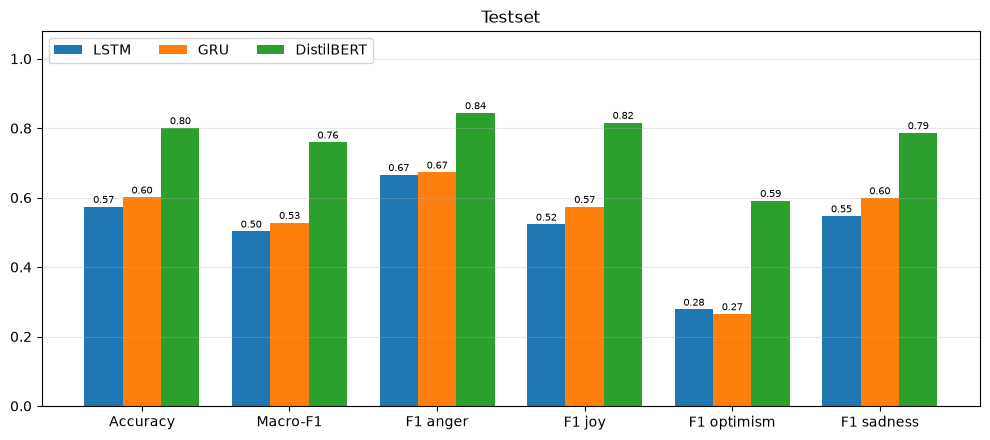

In [11]:
# Balkendiagramm: Accuracy, Macro-F1 und F1 pro Klasse für alle drei Modelle nebeneinander
fig, ax = plt.subplots(figsize=(10, 4.5))
cols = ["tab:blue", "tab:orange", "tab:green"]
width = 0.26
x = np.arange(NUM_CLASSES + 2)  # 2 Gesamtmetriken + 4 Klassen
for i, (name, c) in enumerate(zip(rows, cols)):
    r = rows[name]
    # (i - 1) * width verschiebt die drei Modelle nebeneinander um die Gruppenmitte
    bars = ax.bar(x + (i - 1) * width, [r["acc"], r["f1"]] + list(r["per_class"]), width, color=c, label=name)
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=1)  # Zahlenwert über jeden Balken
ax.set_xticks(x, ["Accuracy", "Macro-F1"] + [f"F1 {c}" for c in CLASSES])
ax.set_ylim(0, 1.08)
ax.set_title("Testset")
ax.legend(loc="upper left", ncols=3)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()